# Fitting TDB parameters to literature data

`fit` refits chosen coefficients of a database's parameters by weighted least
squares, to:

- thermochemical data (mixing and formation enthalpies, entropies, heat
  capacities);
- activities;
- phase-equilibrium data, including one-sided boundary points, which enter as
  driving forces.

The result carries the covariance and a fitted `ThermoDatabase`, which feeds
straight back into a certified equilibrium.

This notebook refits the Cu–Mg liquid to the measured thermochemistry curated
for ESPEI (PhasesResearchLab/ESPEI-datasets, CC-BY 4.0), and compares the
result with the published assessment and the data:

- liquid mixing enthalpies: V. N. Batalin et al., Izv. Akad. Nauk SSSR Met.
  (1987); F. Sommer et al., Z. Metallkd. 74 (1983);
- liquid Mg activities: S. P. Garg, Y. J. Bhatt and C. V. Sundaram, Metall.
  Trans. 4 (1973) 283–289;
- the assessment to compare with: the NIMS Cu–Mg file (`cumg_nims`), after
  C. A. Coughanowr, I. Ansara, R. Luoma, M. Hämäläinen and H. L. Lukas,
  Z. Metallkd. 82 (1991) 574–581.

The full fit, with the 238 phase-boundary points and the compounds, is
`examples/cumg_espei_fit.py` (about 17 minutes).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from discopt.calphad import databases, equilibrium
from discopt.calphad.equilibrium.common import R_GAS
from discopt.calphad.fit import Dataset, fit
from discopt.calphad.ops import NUM

EL = ("CU", "MG")
assessed = databases.load("cumg_nims")
data = Dataset.from_espei(
    Path("..") / "examples" / "data" / "espei-cu-mg", assessed, EL, phase_map={"LAVES_C15": "CU2MG"}
)
liquid_data = Dataset([o for o in data if o.phase == "LIQUID" and o.kind in ("HM_MIX", "ACR")])
print(f"{len(liquid_data)} liquid observations:", {k: sum(o.kind == k for o in liquid_data) for k in ("HM_MIX", "ACR")})
print("sources:", sorted({o.citation.split(";")[0] for o in liquid_data if o.citation}))

43 liquid observations: {'HM_MIX': 34, 'ACR': 9}
sources: ['Batalin1987', 'garg1973thermodynamic', 'sommer1983calorimetric_investigations']


## Refit the liquid L0 and L1

Each interaction gets the form a + b·T. The fit starts from the assessment's
values and iterates linearized solves.

In [2]:
free = {"L(LIQUID,CU,MG;0)": "a + b*T", "L(LIQUID,CU,MG;1)": "a + b*T"}
res = fit(assessed, liquid_data, EL, free)
print(res.summary())

fit of 4 coefficients to 43 observations (43 residuals): chi2 = 52.1, dof = 39, rank = 4
  L(LIQUID,CU,MG;0).a              = -34177.2  ± 404
  L(LIQUID,CU,MG;0).b              =  3.73641  ± 0.486
  L(LIQUID,CU,MG;1).a              = -6774.25  ± 1.32e+03
  L(LIQUID,CU,MG;1).b              = -1.5088  ± 1.27
  ACR         9 rows, RMS weighted residual 1.24
  HM_MIX     34 rows, RMS weighted residual 1.06


In [3]:
for label in free:
    tdb_label = label.replace("L(", "G(")  # interactions are G(...) in the TDB file; fit accepts L(...)
    p = next(q for q in assessed.parameters if q.label == tdb_label)
    print(f"{label}: assessment  {assessed.expand(p.function)}")
for name, value, std in zip(res.names, res.values, res.std):
    print(f"  fit {name:24s} {value:12.2f} ± {std:.2f}")

L(LIQUID,CU,MG;0): assessment  4.75612*T - 36984.0
L(LIQUID,CU,MG;1): assessment  -8191.29000000000
  fit L(LIQUID,CU,MG;0).a         -34177.20 ± 404.20
  fit L(LIQUID,CU,MG;0).b              3.74 ± 0.49
  fit L(LIQUID,CU,MG;1).a          -6774.25 ± 1321.22
  fit L(LIQUID,CU,MG;1).b             -1.51 ± 1.27


## Mixing enthalpy of the liquid: data, fit and assessment

H_mix = H − Σ x_i H_i with H = G − T ∂G/∂T, by central differences in T. The
data were measured at 1100–1373 K; H_mix of this liquid barely depends on T.

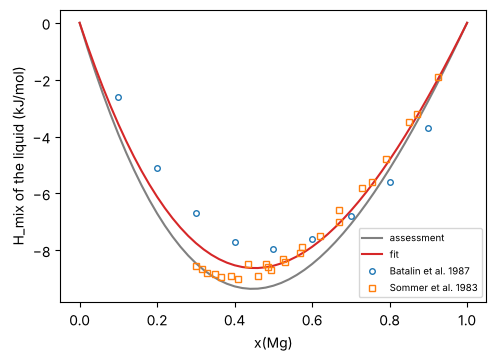

In [4]:
def h_mix(db, x_cu, T, h=0.01):
    liq = db.phase_models(EL)["LIQUID"]

    def H(x):
        g = lambda t: float(liq.gibbs(np.array([x]), NUM, t)) * R_GAS * t  # noqa: E731
        return g(T) - T * (g(T + h) - g(T - h)) / (2 * h)

    return H(x_cu) - x_cu * H(1.0) - (1 - x_cu) * H(0.0)


def x_cu(o):
    return o.x if o.x is not None else o.site_fractions[0]["CU"]


T_PLOT = 1373.0
xs = np.linspace(0.0, 1.0, 51)
fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.plot(1 - xs, [h_mix(assessed, x, T_PLOT) / 1000 for x in xs], color="0.5", label="assessment")
ax.plot(1 - xs, [h_mix(res.database, x, T_PLOT) / 1000 for x in xs], color="C3", label="fit")
for cite, marker in zip(sorted({o.citation for o in liquid_data if o.kind == "HM_MIX"}), "osd^v"):
    pts = [(1 - x_cu(o), o.value / 1000) for o in liquid_data if o.kind == "HM_MIX" and o.citation == cite]
    names = {"Batalin1987": "Batalin et al. 1987", "sommer1983calorimetric_investigations": "Sommer et al. 1983"}
    ax.plot(*zip(*pts), marker, ms=4, mfc="none", label=names.get(cite.split(";")[0], cite))
ax.set_xlabel("x(Mg)")
ax.set_ylabel("H_mix of the liquid (kJ/mol)")
ax.legend(fontsize=7)
plt.show()

## Weighted residuals by kind of data

In [5]:
for kind, (n, rms) in res.residuals_by_kind().items():
    print(f"{kind:7s} {n:3d} rows, RMS weighted residual {rms:.2f}")

ACR       9 rows, RMS weighted residual 1.24
HM_MIX   34 rows, RMS weighted residual 1.06


## The fitted database in a certified equilibrium

`res.database` is an ordinary `ThermoDatabase`. A Mg-rich liquid at 800 K,
certified with the fitted parameters:

In [6]:
phases = list(res.database.phase_models(EL).values())
r = equilibrium(phases, x=0.15, T=800.0)
print(r.summary())

CERTIFIED_TO_TOLERANCE after 1 iteration(s); T = 800 K; eps = 1e-05 RT
  mu/RT = [-9.22887898 -5.11067233]   G/RT = -5.7284033240
  LIQUID: x = [0.15 0.85]  amount = 1.00000000
  pricing LIQUID: LB = -3.839e-06  UB = 8.882e-16
  pricing FCC_A1: LB = 3.192e-02  UB = 1.286e-01
  pricing HCP_A3: LB = 3.546e-02  UB = 3.546e-02
  pricing CU2MG: LB = 6.560e-02  UB = 2.392e+00
  pricing CUMG2: LB = 1.247e-01  UB = 1.247e-01
  G_R - G_global <= 3.839e-06 RT (residual 8.9e-16)


L1 agrees with the assessment within its uncertainty. L0 comes out about
2.8 kJ/mol less negative (several σ): the thermochemistry alone pulls it that
way, while the assessment balanced it against the phase diagram, which this
liquid-only fit ignores. The weighted residuals are near 1, so the data are
described to within their stated uncertainties. The full example adds the
boundary data and the compounds.